# EDA 08 — Lending Club (2007 – 2018Q4)

Nguồn: Kaggle (wordsforthewise) — toàn bộ khoản vay P2P được **chấp nhận** (2,26 triệu, 151 cột) và hồ sơ **bị từ chối**
(27,6 triệu, 9 cột). File: `data/interim/lending_club/{accepted,rejected}.parquet`.

Nhãn được suy ra từ `loan_status`:
`Charged Off`, `Default`, `Does not meet the credit policy. Status:Charged Off` → 1;
`Fully Paid`, `Does not meet the credit policy. Status:Fully Paid` → 0;
các khoản **chưa kết thúc** (`Current`, `Late`, `In Grace Period`) → `target = NaN` (chưa biết kết cục).

Phần lớn phân tích bên dưới chỉ dùng các khoản đã kết thúc (*resolved*) và các biến có tại thời điểm cho vay.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.visualization import eda

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
INTERIM = ROOT / "data" / "interim"

## 1. Nạp dữ liệu

In [2]:
NAME = "lending_club"
LC = INTERIM / "lending_club"
APP_COLS = ["loan_amnt", "term", "int_rate", "installment", "grade", "emp_length", "home_ownership",
            "annual_inc", "verification_status", "purpose", "dti", "delinq_2yrs", "fico_range_low",
            "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc",
            "mort_acc", "pub_rec_bankruptcies", "application_type"]
POST_COLS = ["recoveries", "total_rec_prncp", "total_pymnt", "last_fico_range_high", "debt_settlement_flag"]
full = pd.read_parquet(LC / "accepted.parquet", columns=APP_COLS + POST_COLS + ["issue_d", "loan_status", "target"])
full["issue_year"] = pd.to_datetime(full["issue_d"], format="%b-%Y").dt.year
print("Tất cả khoản vay:", full.shape)
print(full["loan_status"].value_counts(dropna=False))
df = full[full["target"].notna()].drop(columns=POST_COLS + ["issue_d", "loan_status"]).copy()
df["target"] = df["target"].astype(int)
df.shape

Tất cả khoản vay: (2260668, 31)
loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
Name: count, dtype: int64


(1348099, 24)

## 2. Tổng quan

In [3]:
ov = eda.overview(df)
display(ov.to_frame("value"))
display(df.head())

,value
rows,1348099.00
features,23.00
numeric_features,16.00
categorical_features,7.00
duplicate_rows,0.00
cells_missing_pct,0.41
features_with_missing,11.00


,loan_amnt,term,int_rate,installment,grade,emp_length,home_ownership,annual_inc,verification_status,purpose,dti,delinq_2yrs,fico_range_low,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,mort_acc,pub_rec_bankruptcies,application_type,target,issue_year
0,3600.0,36 months,13.99,123.03,C,10+ years,MORTGAGE,55000.0,Not Verified,debt_consolidation,5.91,0.0,675.0,1.0,7.0,0.0,2765.0,29.7,13.0,1.0,0.0,Individual,0,2015
1,24700.0,36 months,11.99,820.28,C,10+ years,MORTGAGE,65000.0,Not Verified,small_business,16.06,1.0,715.0,4.0,22.0,0.0,21470.0,19.2,38.0,4.0,0.0,Individual,0,2015
2,20000.0,60 months,10.78,432.66,B,10+ years,MORTGAGE,63000.0,Not Verified,home_improvement,10.78,0.0,695.0,0.0,6.0,0.0,7869.0,56.2,18.0,5.0,0.0,Joint App,0,2015
4,10400.0,60 months,22.45,289.91,F,3 years,MORTGAGE,104433.0,Source Verified,major_purchase,25.37,1.0,695.0,3.0,12.0,0.0,21929.0,64.5,35.0,6.0,0.0,Individual,0,2015
5,11950.0,36 months,13.44,405.18,C,4 years,RENT,34000.0,Source Verified,debt_consolidation,10.20,0.0,690.0,0.0,5.0,0.0,8822.0,68.4,6.0,0.0,0.0,Individual,0,2015


## 3. Nhãn (target: 1 = xấu / vỡ nợ, 0 = tốt)

{'n': 1348099, 'n_bad': 269360, 'n_good': 1078739, 'bad_rate_pct': 19.98, 'imbalance_ratio': 4.0}


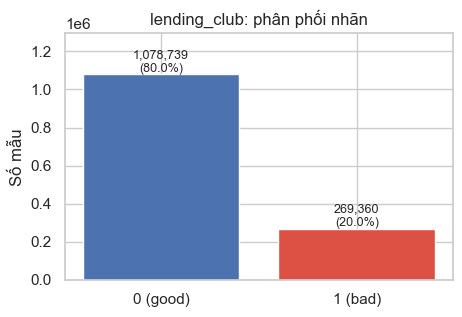

In [4]:
tgt = eda.target_summary(df["target"])
print(tgt)
eda.plot_target(df["target"], NAME)

## 4. Giá trị thiếu

Bảng thứ hai so sánh tỉ lệ nợ xấu khi cột bị thiếu và khi có giá trị: chênh lệch lớn nghĩa là *bản thân việc thiếu* đã mang thông tin về nhãn.

In [5]:
miss = eda.missing_table(df)
display(miss if len(miss) else "Không có giá trị thiếu (NaN).")
mvt = eda.missing_vs_target(df)
display(mvt if len(mvt) else "Không có cột nào đủ lượng thiếu để so sánh bad rate.")

,missing_pct
emp_length,5.83
mort_acc,3.71
pub_rec_bankruptcies,0.10
revol_util,0.07
dti,0.03


,feature,missing_pct,bad_rate_if_missing,bad_rate_if_present,gap
0,inq_last_6mths,0.00,10.00,19.98,-9.98
1,emp_length,5.83,26.93,19.55,7.38
2,mort_acc,3.71,15.28,20.16,-4.88
3,pub_rec_bankruptcies,0.10,24.47,19.98,4.49
4,dti,0.03,18.98,19.98,-1.00
5,revol_util,0.07,20.74,19.98,0.76


## 5. Hồ sơ các biến số

`skew`/`kurtosis`: độ lệch và độ nhọn; `outlier_iqr_pct`: % điểm nằm ngoài 1.5×IQR; `zero_pct`: % giá trị 0; `auc`: AUC đơn biến (max(AUC, 1−AUC)) — thước đo nhanh sức phân biệt của từng biến.

In [6]:
prof = eda.numeric_profile(df)
cols_show = ["n_unique", "min", "median", "max", "skew", "kurtosis", "outlier_iqr_pct", "zero_pct", "auc"]
display(prof.sort_values("auc", ascending=False)[cols_show])
print("Số cột số có |skew| > 2:", int((prof["skew"].abs() > 2).sum()), "/", len(prof))

,n_unique,min,median,max,skew,kurtosis,outlier_iqr_pct,zero_pct,auc
feature,,,,,,,,,
int_rate,672,5.31,12.74,30.99,0.713,0.508,1.853,0.000,0.683
fico_range_low,48,610.00,690.00,845.00,1.284,1.662,3.451,0.000,0.593
dti,7067,-1.00,17.61,999.00,27.092,2112.139,0.407,0.065,0.577
mort_acc,39,0.00,1.00,51.00,1.637,5.193,1.371,40.357,0.556
loan_amnt,1560,500.00,12000.00,40000.00,0.783,-0.082,0.531,0.000,0.551
annual_inc,64462,0.00,65000.00,10999200.00,46.240,4803.310,4.898,0.027,0.548
installment,83531,4.93,375.04,1719.83,1.007,0.750,3.130,0.000,0.543
revol_util,1379,0.00,52.20,892.30,-0.037,0.240,0.005,0.524,0.543
inq_last_6mths,28,0.00,0.00,33.00,2.021,10.073,5.445,57.175,0.542


Số cột số có |skew| > 2: 7 / 16


## 6. Phân phối theo nhãn

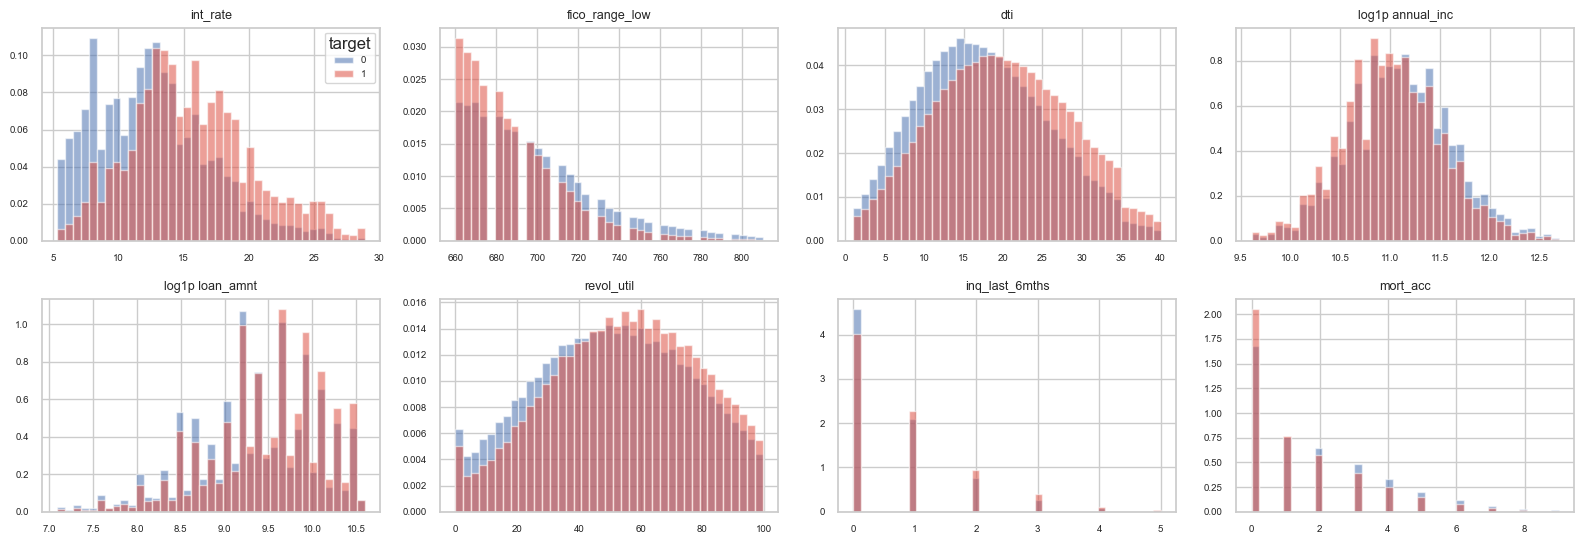

In [7]:
top = ["int_rate", "fico_range_low", "dti", "annual_inc", "loan_amnt", "revol_util", "inq_last_6mths", "mort_acc"]
eda.plot_numeric_by_target(df, top, NAME, log=["annual_inc", "loan_amnt"])

## 7. Biến phân loại: tỉ lệ nợ xấu theo nhóm

Đường nét đứt = bad rate chung.

n  bad_rate  share_pct
feature             level                                           
term                 36 months          1023206     16.02      75.90
                     60 months           324893     32.45      24.10
grade               A                    235193      6.04      17.45
                    B                    393102     13.40      29.16
                    C                    382323     22.44      28.36
                    D                    201657     30.38      14.96
                    E                     94192     38.43       6.99
                    F                     32306     45.15       2.40
                    G                      9326     49.67       0.69
home_ownership      MORTGAGE             666852     17.23      49.47
                    OWN                  145027     20.63      10.76
                    RENT                 535699     23.23      39.74
verification_status Not Verified         407541     14.74      30.23
                    Source Verified      521579     20.96      38.69
                    Verified             418979     23.86      31.08
purpose             car                   14652     14.72       1.09
                    credit_card          295625     16.93      21.93
                    debt_consolidation   781442     21.16      57.97
                    home_improvement      87721     17.76       6.51
                    house                  7298     21.91       0.54
                    major_purchase        29550     18.61       2.19
                    medical               15614     21.85       1.16
                    moving                 9526     23.40       0.71
                    other                 78301     21.08       5.81
                    renewable_energy        936     23.72       0.07
                    small_business        15577     29.86       1.16
                    vacation               9084     19.20       0.67
                    wedding                2350     12.43       0.17
emp_length          1 year                88843     20.59       6.59
                    10+ years            442679     18.80      32.84
                    2 years              122100     19.82       9.06
                    3 years              107868     19.99       8.00
                    4 years               80763     19.76       5.99
                    5 years               84326     19.62       6.26
                    6 years               62879     19.38       4.66
                    7 years               59724     19.51       4.43
                    8 years               60811     19.96       4.51
                    9 years               51019     19.91       3.78
                    < 1 year             108537     20.54       8.05
                    <NA>                  78550     26.93       5.83

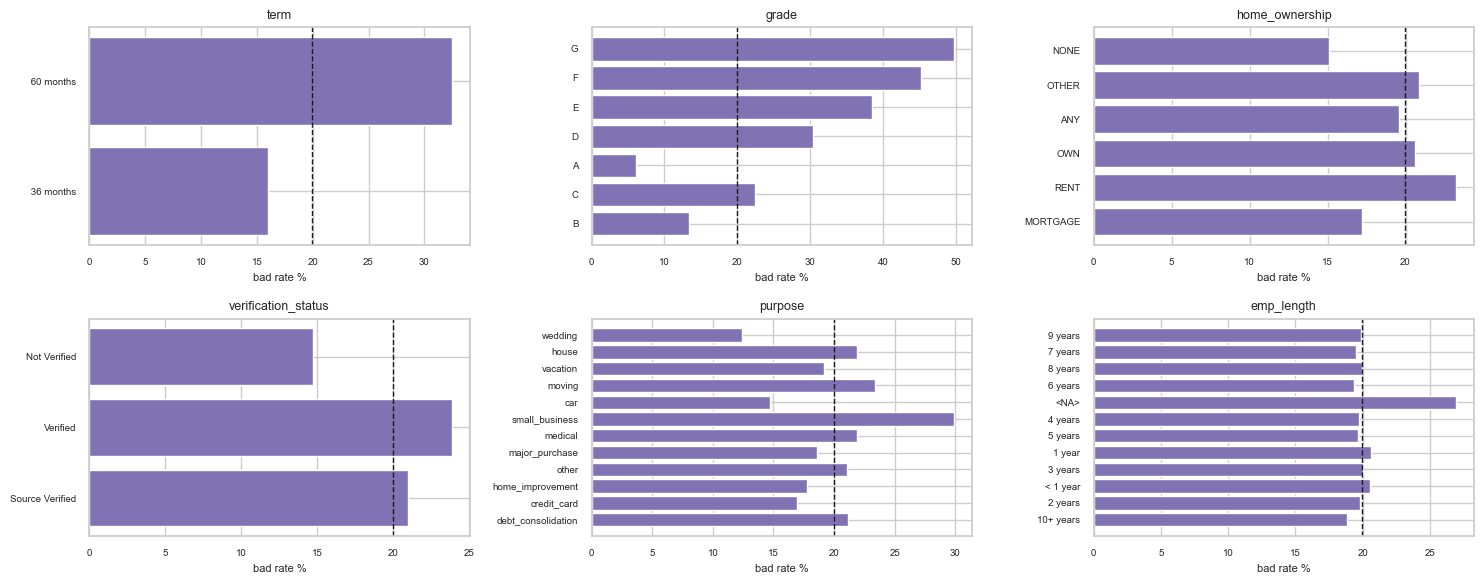

In [8]:
cats = ["term", "grade", "home_ownership", "verification_status", "purpose", "emp_length"]
display(eda.categorical_bad_rate(df, cats).query("n >= 500"))
eda.plot_categorical_bad_rate(df, cats, NAME)

## 8. Tương quan

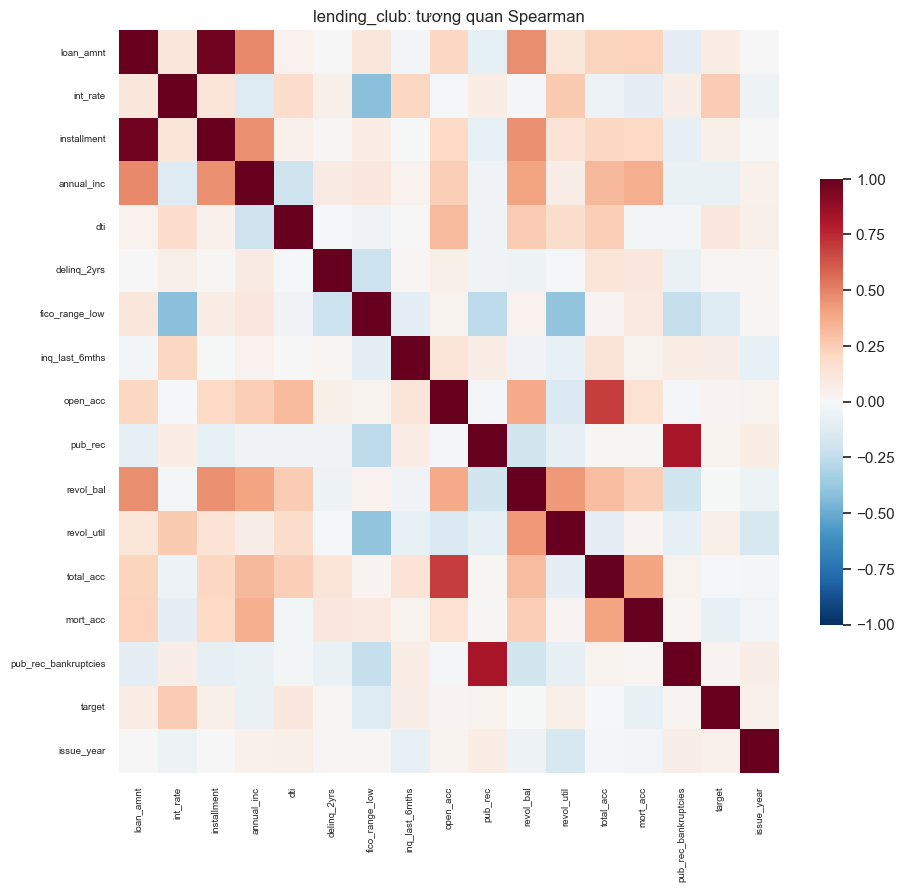

,a,b,spearman
0,loan_amnt,installment,0.969255


In [9]:
corr = eda.correlation_heatmap(df, NAME)
display(eda.high_corr_pairs(corr, thr=0.9).head(20))

## 9. Kiểm tra riêng cho bộ dữ liệu

### Nhãn phụ thuộc thời gian (vintage) và khoản chưa kết thúc

,n,resolved_pct,bad_rate_resolved
issue_year,,,
2007,603,100.0,26.2
2008,2393,100.0,20.7
2009,5281,100.0,13.7
2010,12537,100.0,14.0
2011,21721,100.0,15.2
2012,53367,100.0,16.2
2013,134814,100.0,15.6
2014,235629,94.7,18.4
2015,421095,89.2,20.2


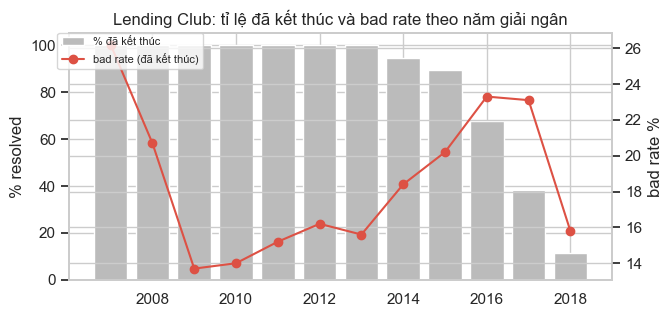

In [10]:
by_year = full.groupby("issue_year").agg(
    n=("loan_status", "size"),
    resolved_pct=("target", lambda s: 100 * s.notna().mean()),
    bad_rate_resolved=("target", lambda s: 100 * s.mean()),
).round(1)
display(by_year)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(by_year.index, by_year["resolved_pct"], color="#bbb", label="% đã kết thúc")
ax2 = ax.twinx()
ax2.plot(by_year.index, by_year["bad_rate_resolved"], "o-", color="#DD5144", label="bad rate (đã kết thúc)")
ax.set_ylabel("% resolved"); ax2.set_ylabel("bad rate %")
ax.set_title("Lending Club: tỉ lệ đã kết thúc và bad rate theo năm giải ngân")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.9), fontsize=8)
eda.savefig(fig, f"{NAME}_vintage")
plt.show()

### Rò rỉ thông tin từ các biến sau khi giải ngân

In [11]:
from sklearn.metrics import roc_auc_score
res = full[full["target"].notna()]
rows = []
for c in ["recoveries", "total_rec_prncp", "last_fico_range_high", "int_rate", "fico_range_low"]:
    ok = res[c].notna()
    a = roc_auc_score(res.loc[ok, "target"], res.loc[ok, c])
    rows.append({"feature": c, "kind": "post-loan (leak)" if c in POST_COLS else "application", "auc": round(max(a, 1 - a), 3)})
display(pd.DataFrame(rows))
display(res.groupby("debt_settlement_flag")["target"].agg(["size", "mean"]))

,feature,kind,auc
0,recoveries,post-loan (leak),0.844
1,total_rec_prncp,post-loan (leak),0.875
2,last_fico_range_high,post-loan (leak),0.939
3,int_rate,application,0.683
4,fico_range_low,application,0.593


,size,mean
debt_settlement_flag,,
N,1314807,0.17955
Y,33292,0.99985


### Giá trị bất thường và mức độ thiếu của bảng đầy đủ

In [12]:
import pyarrow.parquet as pq
t = pq.read_table(LC / "accepted.parquet")
null_pct = pd.Series({c: t[c].null_count / t.num_rows for c in t.column_names})
print(f"Cột thiếu > 50%: {(null_pct > 0.5).sum()} / {len(null_pct)};  > 90%: {(null_pct > 0.9).sum()}")
del t
print("annual_inc: max =", f"{df.annual_inc.max():,.0f}", "| = 0:", (df.annual_inc == 0).sum())
print("dti: min =", df.dti.min(), "| max =", df.dti.max(), "| > 100:", (df.dti > 100).sum())

Cột thiếu > 50%: 44 / 152;  > 90%: 38
annual_inc: max = 10,999,200 | = 0: 361
dti: min = -1.0 | max = 999.0 | > 100: 533


### Hồ sơ bị từ chối

In [13]:
rej = pd.read_parquet(LC / "rejected.parquet", columns=["Application Date", "Risk_Score", "Amount Requested"])
rej_year = pd.to_datetime(rej["Application Date"]).dt.year
cmp = pd.DataFrame({"accepted": full.groupby("issue_year").size(), "rejected": rej_year.value_counts().sort_index()})
cmp["acceptance_pct"] = (100 * cmp.accepted / (cmp.accepted + cmp.rejected)).round(1)
display(cmp)
print(f"Risk_Score thiếu ở {rej.Risk_Score.isna().mean():.0%} hồ sơ bị từ chối; median = {rej.Risk_Score.median():.0f} "
      f"(accepted fico_range_low median = {full.fico_range_low.median():.0f})")

,accepted,rejected,acceptance_pct
2007,603,5274,10.3
2008,2393,25596,8.5
2009,5281,56991,8.5
2010,12537,112561,10.0
2011,21721,217792,9.1
2012,53367,337277,13.7
2013,134814,760942,15.1
2014,235629,1933700,10.9
2015,421095,2859379,12.8
2016,434407,4769874,8.3


Risk_Score thiếu ở 67% hồ sơ bị từ chối; median = 637 (accepted fico_range_low median = 690)


## 10. Nhận xét

- **Nhãn không có sẵn mà phải suy ra**, và **~40% khoản vay chưa có kết cục** (`Current`/`Late`) → phải loại bỏ. Trên 1,35 triệu khoản đã kết thúc, bad rate ≈ **20%** (≈ 4:1).
- **Nhãn phụ thuộc thời gian — bất thường quan trọng nhất:** bad rate theo năm giải ngân dao động 14% → 23%; các năm 2017–2018 chỉ có 11–38% khoản đã kết thúc, nên mẫu “đã kết thúc” bị **thiên lệch** (khoản vỡ nợ sớm hoặc trả sớm). Kỳ hạn 60 tháng có bad rate gấp đôi 36 tháng (≈ 32% vs 16%). → cần chia train/test theo thời gian, không chia ngẫu nhiên.
- **Rò rỉ thông tin nghiêm trọng:** nhiều cột chỉ có sau khi giải ngân (`recoveries`, `total_rec_prncp`, `last_fico_range_*`, `debt_settlement_flag`…) cho AUC 0,84–0,94 và `debt_settlement_flag = Y` ⇒ bad ≈ 100%. Phải loại khỏi đặc trưng.
- **Nhãn gắn chặt với xếp hạng nội bộ:** bad rate tăng đều từ grade A (~6%) tới G (~50%); `int_rate` (AUC ≈ 0,68) là biến mạnh nhất vì nó *được định giá từ* rủi ro.
- **Thiên lệch chọn mẫu (selection bias):** chỉ có nhãn cho khoản được duyệt; tỉ lệ chấp nhận chỉ ~5–15% số hồ sơ (giảm còn ~5% năm 2018), điểm rủi ro của hồ sơ bị từ chối thấp hơn rõ (median 637 so với 690). Mô hình học trên đó không đại diện cho toàn bộ người nộp đơn (vấn đề *reject inference*).
- **Phân phối:** `annual_inc` cực lệch (max ≈ 11 triệu USD trong mẫu đã kết thúc, 110 triệu trong toàn bộ; 361 người thu nhập = 0), `dti` có giá trị -1 và 999 (mã lỗi, 533 dòng > 100); 44/152 cột thiếu > 50% (biến mới chỉ có từ ~2015, biến cho khoản vay chung).

In [14]:
EXTRA = {"resolved_rows": int(len(df)), "all_rows": int(len(full)), "unresolved_pct": round(100 * full.target.isna().mean(), 2)}
eda.save_summary(NAME, {
    "name": NAME,
    "overview": ov.to_dict(),
    "target": tgt,
    "missing_top": miss["missing_pct"].head(10).to_dict() if len(miss) else {},
    "n_numeric_abs_skew_gt2": int((prof["skew"].abs() > 2).sum()),
    "n_numeric": int(len(prof)),
    "max_abs_skew": float(prof["skew"].abs().max()),
    "top_auc": prof["auc"].sort_values(ascending=False).head(5).to_dict(),
    **EXTRA,
})